# MwC 05 — figures and audit

Create the selected MwC raincloud figure and audit the five-step MwC workflow.

- Formal analysis universe: 12 cortical + 14 limbic ROIs (26 nodes)
- Cross-network connectivity: 12 × 14 = 168 edges
- Pipeline: `mwc`; step 5 of 5
- Run mode: standalone; all prerequisite steps load automatically in the same kernel.


,input,size_kib
0,03_compute_normative_sc_mwc.py,12.4
1,session_gcmi_pet_AAL3_144.npz,19663.6
2,normative_SC_top10_mask.npz,53.7
3,subject_level_corticolimbic26_normativeSC10_Mw...,139.7
4,subject_level_AAL3_144_normativeSC10_MwC_wide....,333.6
5,validation_report.json,0.2
6,corticolimbic_12x14_ROI_definition.csv,0.6
7,clinical_data.xlsx,12.6
8,subject_level_corticolimbic26_age_sex_adjusted...,154.9


{
  "full_144": "./outputs/mwc/recomputed_normative_sc/subject_level_AAL3_144_normativeSC10_MwC_wide.csv.gz",
  "selected_26": "./outputs/mwc/recomputed_normative_sc/subject_level_corticolimbic26_normativeSC10_MwC_wide.csv",
  "validation": "./outputs/mwc/recomputed_normative_sc/calculation_validation_report.json"
}
PASS: AAL3-144 normative-SC-constrained MwC recomputed before 26-ROI extraction


,check,passed
0,sessions_291,True
1,retained_AAL3_nodes_144,True
2,fixed_dTOR_normative_SC_edges_1030,True
3,gcmi_floor_bits_0p01,True
4,row_normalization_error_below_1e_12,True
5,all_144_nodes_computed_before_26_extraction,True
6,isolated_nodes_remain_missing,True
7,full_144_matches_validated_reference,True
8,selected_26_matches_validated_reference,True


,quantity,value
0,upstream paired sessions,291.0
1,clinical sessions,291.0
2,ROIs per session,26.0
3,long-table rows,7566.0
4,all-144 to 26 extraction maximum absolute error,0.0


,node_index,network,AAL3_ID,ROI
0,1,cortical,3,Frontal_Sup_2_L
1,2,cortical,4,Frontal_Sup_2_R
2,3,cortical,5,Frontal_Mid_2_L
3,4,cortical,6,Frontal_Mid_2_R
4,5,cortical,19,Frontal_Sup_Medial_L
5,6,cortical,20,Frontal_Sup_Medial_R
6,7,cortical,21,Frontal_Med_Orb_L
7,8,cortical,22,Frontal_Med_Orb_R
8,9,cortical,25,OFCmed_L
9,10,cortical,26,OFCmed_R


,n_ROIs,cortical_ROIs,limbic_ROIs,TRD1_n,TRD2_n,pearson_r,pearson_p_two_sided,same_direction_agreement,DSC_weighted,MwC_input
0,26,12,14,35,104,0.970751,0.0,0.923077,0.819914,HC-only age/sex residual z scores; 26 ROIs ext...


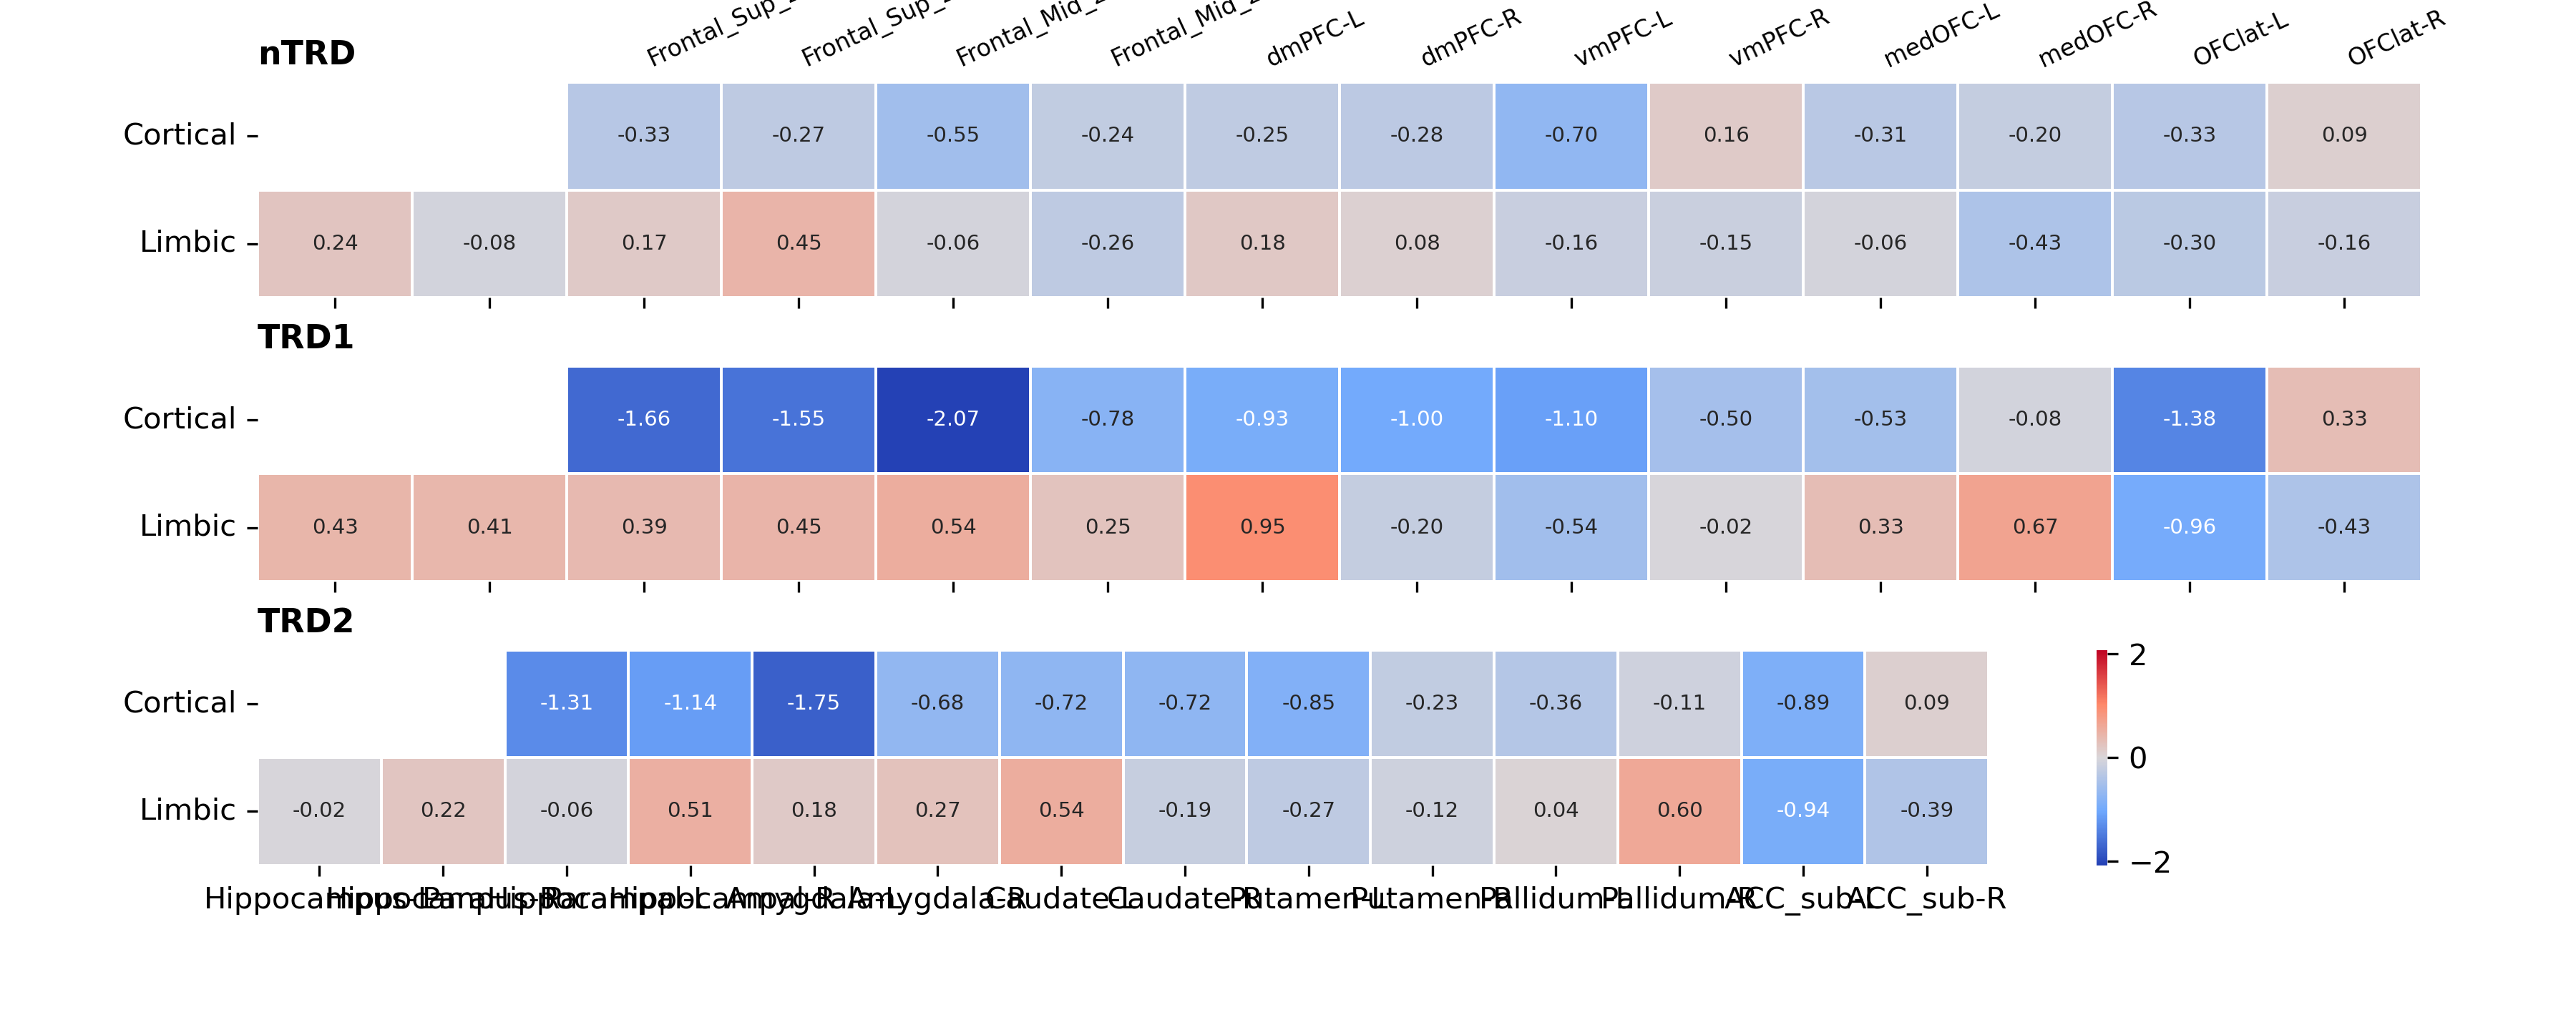

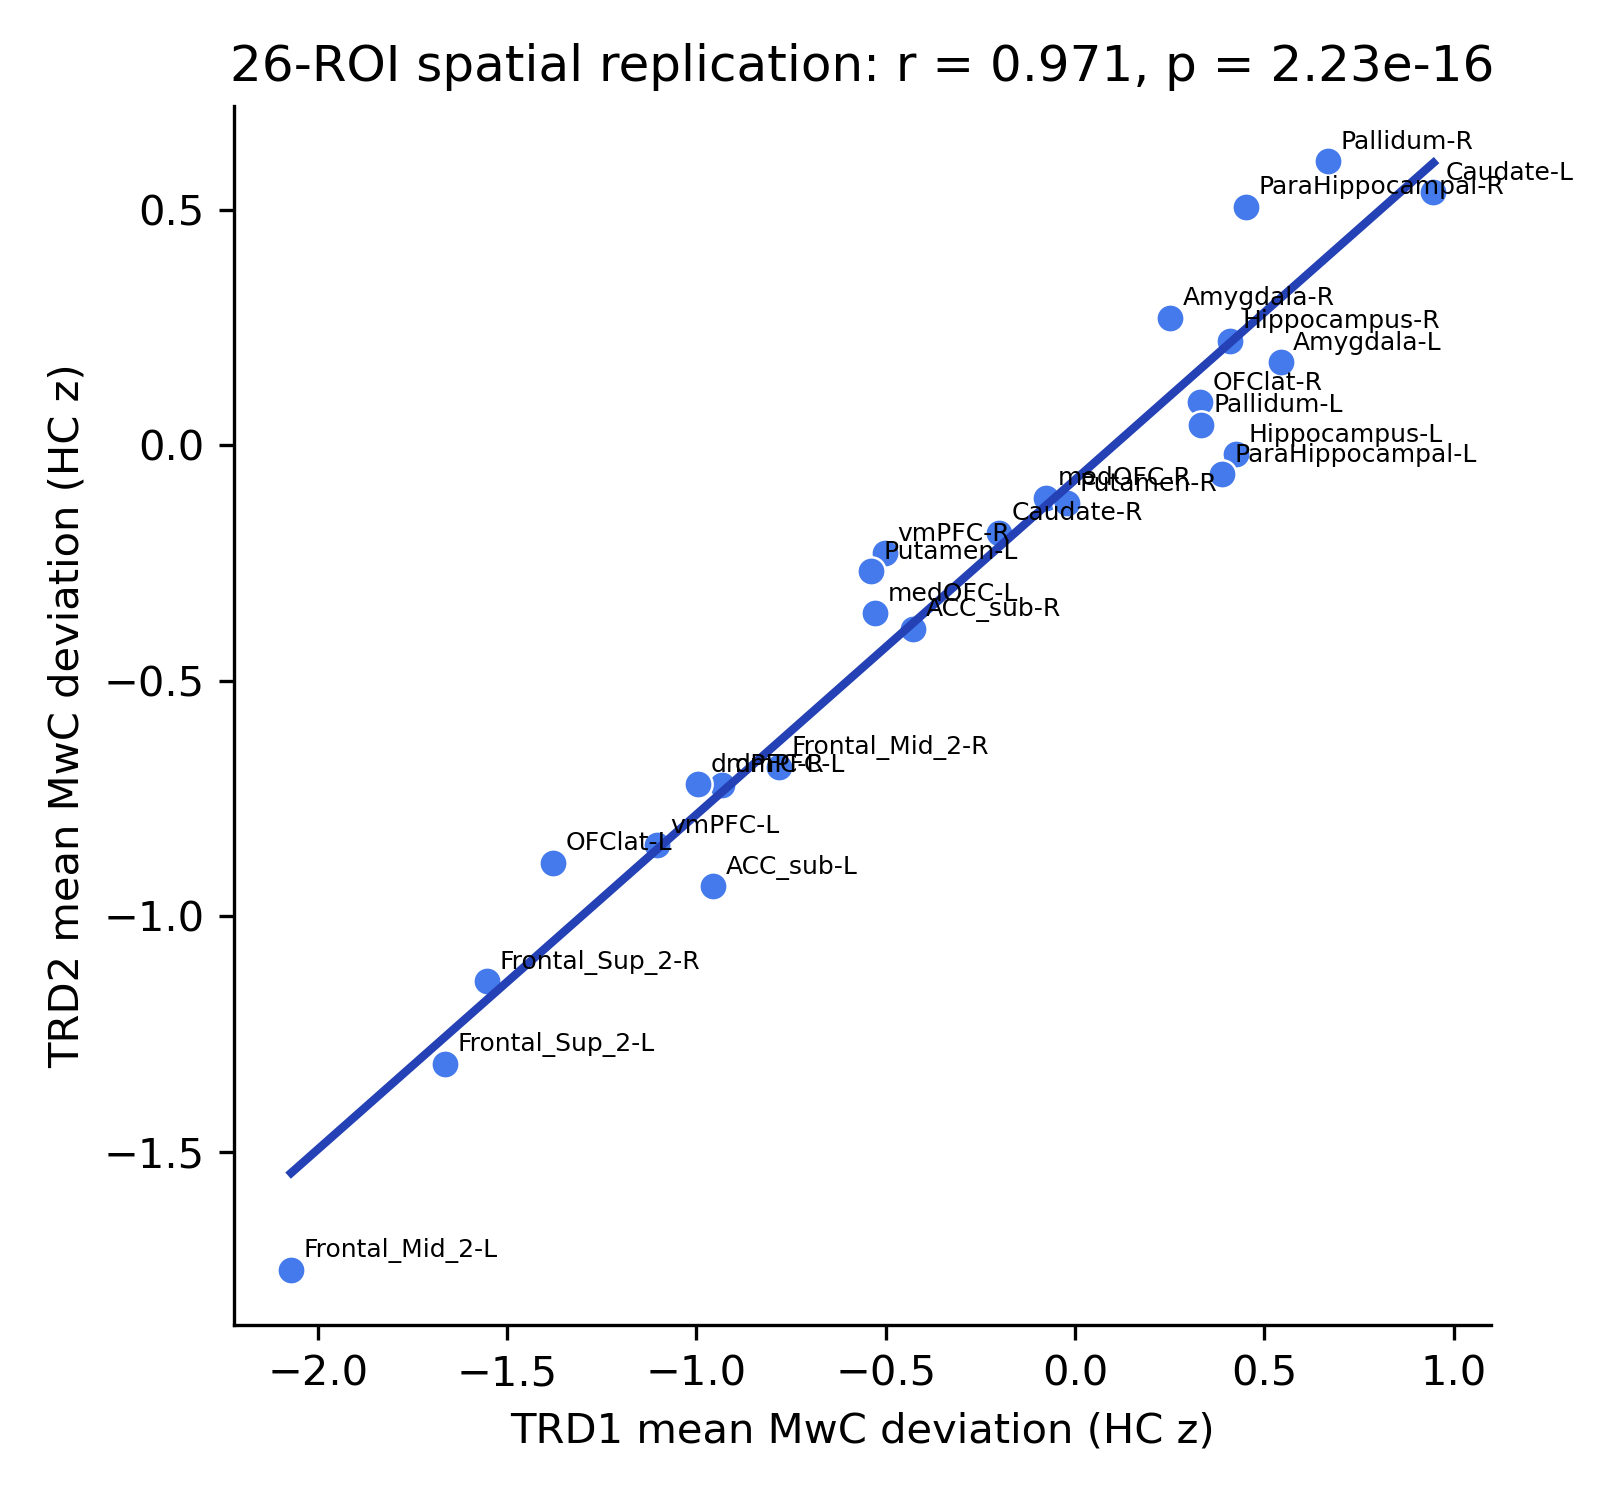

,region,metric,comparison,covariates,n_nTRD,n_TRD,nTRD_mean_HC_z,nTRD_sd_HC_z,TRD_mean_HC_z,TRD_sd_HC_z,beta_TRD_minus_nTRD_HC_SD,hc3_se,ci95_low_TRD_minus_nTRD_HC_SD,ci95_high_TRD_minus_nTRD_HC_SD,p_adjusted
0,SFG_L,MwC_deviation_Frontal_Sup_2_L,TRD - nTRD,age + sex,25,35,-0.330766,1.225849,-1.663635,1.989599,-1.237044,0.394293,-2.009844,-0.464244,0.001705
1,MFG_L,MwC_deviation_Frontal_Mid_2_L,TRD - nTRD,age + sex,25,35,-0.547601,1.663094,-2.070576,1.973155,-1.469070,0.426474,-2.304944,-0.633195,0.000572
2,vmPFC_R,MwC_deviation_Frontal_Med_Orb_R,TRD - nTRD,age + sex,25,35,0.157078,1.420818,-0.502719,1.116825,-0.767800,0.366137,-1.485416,-0.050184,0.035991
3,PAL_L,MwC_deviation_Pallidum_L,TRD - nTRD,age + sex,25,34,-0.056145,1.195773,0.333766,1.180415,0.570440,0.286103,0.009688,1.131192,0.046171
4,HPC_R,MwC_deviation_Hippocampus_R,TRD - nTRD,age + sex,25,35,-0.076973,0.901990,0.409947,0.986862,0.582871,0.236208,0.119912,1.045830,0.013601
5,AMY_R,MwC_deviation_Amygdala_R,TRD - nTRD,age + sex,25,35,-0.263747,0.985869,0.251930,0.782117,0.477820,0.218350,0.049862,0.905777,0.028646


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)
_run_step("mwc_01_setup_recompute.py")
_run_step("mwc_02_subject_level.py")
_run_step("mwc_03_deviation_spatial.py")
_run_step("mwc_04_group_analysis.py")


## Preamble


In [2]:
"""Auto-extracted pipeline step: MwC 05 — final raincloud figures and scope audit.

Do not edit generated copies independently of the source notebooks.
"""


'Auto-extracted pipeline step: MwC 05 — final raincloud figures and scope audit.\n\nDo not edit generated copies independently of the source notebooks.\n'

## Source 14


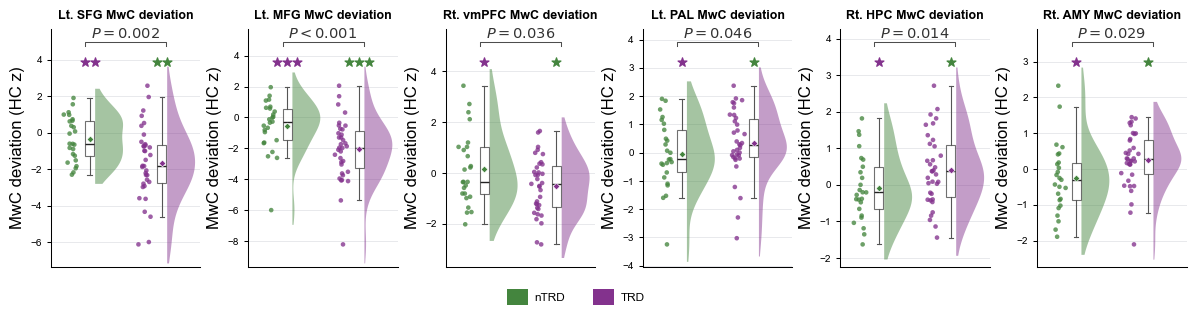

Wrote:
 - ./outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.png
 - ./outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.pdf
 - ./outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.svg


In [3]:
COLORS = {"nTRD": "#44853E", "TRD1": "#83328D"}
GROUPS = ["nTRD", "TRD1"]
GROUP_LABELS = {"nTRD": "nTRD", "TRD1": "TRD"}
GROUP_SPACING = 0.80
GROUP_POSITIONS = {group: index * GROUP_SPACING for index, group in enumerate(GROUPS)}
P_VALUE_FONTSIZE = 10.5
YLABEL_FONTSIZE = 12.0
STAR_SIZE = 45

PLOT_METRICS = [
    {"region": "SFG_L", "title": "Lt. SFG MwC deviation"},
    {"region": "MFG_L", "title": "Lt. MFG MwC deviation"},
    {"region": "vmPFC_R", "title": "Rt. vmPFC MwC deviation"},
    {"region": "PAL_L", "title": "Lt. PAL MwC deviation"},
    {"region": "HPC_R", "title": "Rt. HPC MwC deviation"},
    {"region": "AMY_R", "title": "Rt. AMY MwC deviation"},
]

def configure_style() -> None:
    plt.rcParams.update(
        {
            "font.family": "sans-serif",
            "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
            "font.size": 7.5,
            "axes.labelsize": 8,
            "axes.titlesize": 9,
            "xtick.labelsize": 7.2,
            "ytick.labelsize": 7.2,
            "axes.linewidth": 0.75,
            "xtick.major.width": 0.75,
            "ytick.major.width": 0.75,
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
            "svg.fonttype": "none",
        }
    )


def p_text(p: float) -> str:
    return r"$P < 0.001$" if p < 0.001 else rf"$P = {p:.3f}$"


def density_y(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    spread = float(np.ptp(values))
    pad = max(0.12 * spread, np.std(values, ddof=1) * 0.25, 1e-6)
    y = np.linspace(values.min() - pad, values.max() + pad, 256)
    density = stats.gaussian_kde(values)(y)
    return y, density / density.max()


def add_comparison_bracket(ax: plt.Axes, x1: float, x2: float, y: float, height: float, label: str) -> None:
    ax.plot(
        [x1, x1, x2, x2], [y, y + height, y + height, y],
        color="#4D4D4D", linewidth=0.75, clip_on=False,
    )
    ax.text(
        (x1 + x2) / 2, y + height * 1.35, label,
        ha="center", va="bottom", fontsize=P_VALUE_FONTSIZE, color="#333333",
    )


def raincloud_panel(ax: plt.Axes, frame: pd.DataFrame, specification: dict[str, object], seed: int) -> None:
    rng = np.random.default_rng(seed)
    region = str(specification["region"])
    metric = SELECTED_ROIS[region]
    arrays = {
        group: frame.loc[frame.analysis_cohort.eq(group), metric].dropna().to_numpy(float)
        for group in GROUPS
    }

    for group in GROUPS:
        position = GROUP_POSITIONS[group]
        values = arrays[group]
        color = COLORS[group]
        cloud_x = position - 0.19 + rng.normal(0, 0.035, len(values))
        ax.scatter(cloud_x, values, s=11, color=color, alpha=0.78, edgecolors="none", zorder=3)

        box = ax.boxplot(
            [values], positions=[position], widths=0.10, patch_artist=True,
            showfliers=False, manage_ticks=False,
            medianprops={"color": "#222222", "linewidth": 1.0},
            whiskerprops={"color": "#555555", "linewidth": 0.8},
            capprops={"color": "#555555", "linewidth": 0.8},
            boxprops={"edgecolor": "#555555", "linewidth": 0.8}, zorder=4,
        )
        box["boxes"][0].set_facecolor("white")
        box["boxes"][0].set_alpha(0.84)
        ax.scatter(
            [position], [np.mean(values)], marker="D", s=12,
            facecolor=color, edgecolor="white", linewidth=0.45, zorder=5,
        )

        y, density = density_y(values)
        right = position + 0.06 + 0.31 * density
        ax.fill_betweenx(
            y, position + 0.06, right, facecolor=color, alpha=0.48,
            linewidth=0, edgecolor="none", zorder=1,
        )

    all_values = np.concatenate(list(arrays.values()))
    data_min, data_max = float(all_values.min()), float(all_values.max())
    span = data_max - data_min
    if span == 0:
        span = max(abs(data_max), 1.0)

    row = adjusted_statistics.loc[adjusted_statistics.region.eq(region)].iloc[0]
    bracket_height = 0.025 * span
    bracket_y = data_max + 0.25 * span
    add_comparison_bracket(
        ax, GROUP_POSITIONS["nTRD"] - 0.05, GROUP_POSITIONS["TRD1"] + 0.05,
        bracket_y, bracket_height, p_text(row.p_adjusted),
    )

    # The symbol is determined from this execution's adjusted p value.
    if row.p_adjusted < 0.001:
        star_style, star_count = "solid", 3
    elif row.p_adjusted < 0.01:
        star_style, star_count = "solid", 2
    elif row.p_adjusted < 0.05:
        star_style, star_count = "solid", 1
    elif row.p_adjusted < 0.10:
        star_style, star_count = "outline", 1
    else:
        star_style, star_count = None, 0

    if star_style is not None:
        star_y = data_max + 0.15 * span
        star_offsets = (np.arange(star_count) - (star_count - 1) / 2) * 0.11
        for group, opposite in (("nTRD", "TRD1"), ("TRD1", "nTRD")):
            star_color = COLORS[opposite]
            ax.scatter(
                GROUP_POSITIONS[group] + star_offsets, np.full(star_count, star_y),
                marker="*", s=STAR_SIZE,
                facecolors=star_color if star_style == "solid" else "none",
                edgecolors=star_color, linewidths=0.9, zorder=8,
            )

    ax.set_xlim(-0.43, GROUP_POSITIONS["TRD1"] + 0.43)
    ax.set_ylim(data_min - 0.14 * span, data_max + 0.36 * span)
    ax.set_xticks([GROUP_POSITIONS[group] for group in GROUPS], ["", ""])
    ax.set_ylabel("MwC deviation (HC z)", fontsize=YLABEL_FONTSIZE)
    ax.set_title(str(specification["title"]), pad=7, fontweight="semibold")
    ax.grid(axis="y", color="#D5D8DC", linewidth=0.55, alpha=0.70)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.tick_params(axis="x", bottom=False, length=0)
    ax.tick_params(axis="y", length=3)


configure_style()
fig, axes = plt.subplots(
    1, 6, figsize=(12.3448, 3.40), gridspec_kw={"wspace": 0.32}
)
for index, (ax, specification) in enumerate(zip(axes, PLOT_METRICS)):
    raincloud_panel(ax, baseline, specification, SEED + index)

legend_handles = [
    Patch(facecolor=COLORS[group], edgecolor="none", label=GROUP_LABELS[group])
    for group in GROUPS
]
fig.legend(
    handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, 0.015),
    ncol=2, frameon=False, fontsize=8.5, handlelength=1.75, handleheight=1.75,
    columnspacing=2.4, handletextpad=0.55,
)
fig.subplots_adjust(left=0.075, right=0.995, bottom=0.16, top=0.86)

figure_stem = FIGURE_DIR / "Figure_selected_unilateral_MwC_deviation_raincloud"
fig.savefig(figure_stem.with_suffix(".pdf"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".svg"), bbox_inches="tight")
fig.savefig(figure_stem.with_suffix(".png"), dpi=600, bbox_inches="tight")
plt.show()

print("Wrote:")
for suffix in (".png", ".pdf", ".svg"):
    print(" -", figure_stem.with_suffix(suffix))


## Source 16


In [4]:
expected = [
    MWC_FULL_FILE,
    MWC_WIDE_FILE,
    MWC_CALCULATION_VALIDATION_FILE,
    OUTPUT_DIR / "subject_level_corticolimbic26_normativeSC10_MwC_wide.csv",
    OUTPUT_DIR / "subject_level_corticolimbic26_normativeSC10_MwC_long.csv",
    OUTPUT_DIR / "subject_level_nTRD_TRD1_corticolimbic26_normativeSC10_MwC_HC_reference_deviation.csv",
    MWC_SPATIAL_SUMMARY_FILE,
    OUTPUT_DIR / "nTRD_TRD1_TRD2_normativeSC_MwC_26ROI_mean_deviations.csv",
    MWC_DEVIATION_HEATMAP,
    MWC_DEVIATION_HEATMAP.with_suffix(".pdf"),
    MWC_SPATIAL_FIGURE,
    MWC_SPATIAL_FIGURE.with_suffix(".pdf"),
    OUTPUT_DIR / "ntrd_vs_trd_selected_unilateral_mwc_deviation_age_sex.csv",
    FIGURE_DIR / "Figure_selected_unilateral_MwC_deviation_raincloud.png",
    FIGURE_DIR / "Figure_selected_unilateral_MwC_deviation_raincloud.pdf",
    FIGURE_DIR / "Figure_selected_unilateral_MwC_deviation_raincloud.svg",
]
expected = [Path(output_path).resolve() for output_path in expected]
assert all(output_path.exists() and output_path.stat().st_size > 0 for output_path in expected)
created = [
    output_path.resolve() for output_path in OUTPUT_DIR.rglob("*")
    if output_path.is_file() and output_path.name != ".DS_Store"
]
assert set(expected).issubset(set(created)), sorted(set(expected) - set(created))
allowed_additional = [path for path in created if path not in expected and path.parent == FIGURE_DIR.resolve()]
assert set(created) - set(expected) == set(allowed_additional)
print(f"MwC scope audit passed: {len(created)} normative-SC MwC files.")


MwC scope audit passed: 16 normative-SC MwC files.


## Results preview

Key numerical tables and figures generated by this step are displayed below. The full-resolution files remain under `outputs/`.


### Key tables

**MwC values and adjusted group statistics**  
`outputs/mwc/ntrd_vs_trd_selected_unilateral_mwc_deviation_age_sex.csv` — 6 rows × 15 columns

,region,metric,comparison,covariates,n_nTRD,n_TRD,nTRD_mean_HC_z,nTRD_sd_HC_z,TRD_mean_HC_z,TRD_sd_HC_z,beta_TRD_minus_nTRD_HC_SD,hc3_se,ci95_low_TRD_minus_nTRD_HC_SD,ci95_high_TRD_minus_nTRD_HC_SD,p_adjusted
0,SFG_L,MwC_deviation_Frontal_Sup_2_L,TRD - nTRD,age + sex,25,35,-0.330766,1.225849,-1.663635,1.989599,-1.237044,0.394293,-2.009844,-0.464244,0.001705
1,MFG_L,MwC_deviation_Frontal_Mid_2_L,TRD - nTRD,age + sex,25,35,-0.547601,1.663094,-2.070576,1.973155,-1.469070,0.426474,-2.304944,-0.633195,0.000572
2,vmPFC_R,MwC_deviation_Frontal_Med_Orb_R,TRD - nTRD,age + sex,25,35,0.157078,1.420818,-0.502719,1.116825,-0.767800,0.366137,-1.485416,-0.050184,0.035991
3,PAL_L,MwC_deviation_Pallidum_L,TRD - nTRD,age + sex,25,34,-0.056145,1.195773,0.333766,1.180415,0.570440,0.286103,0.009688,1.131192,0.046171
4,HPC_R,MwC_deviation_Hippocampus_R,TRD - nTRD,age + sex,25,35,-0.076973,0.901990,0.409947,0.986862,0.582871,0.236208,0.119912,1.045830,0.013601
5,AMY_R,MwC_deviation_Amygdala_R,TRD - nTRD,age + sex,25,35,-0.263747,0.985869,0.251930,0.782117,0.477820,0.218350,0.049862,0.905777,0.028646


### Figures

**`outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.png`**

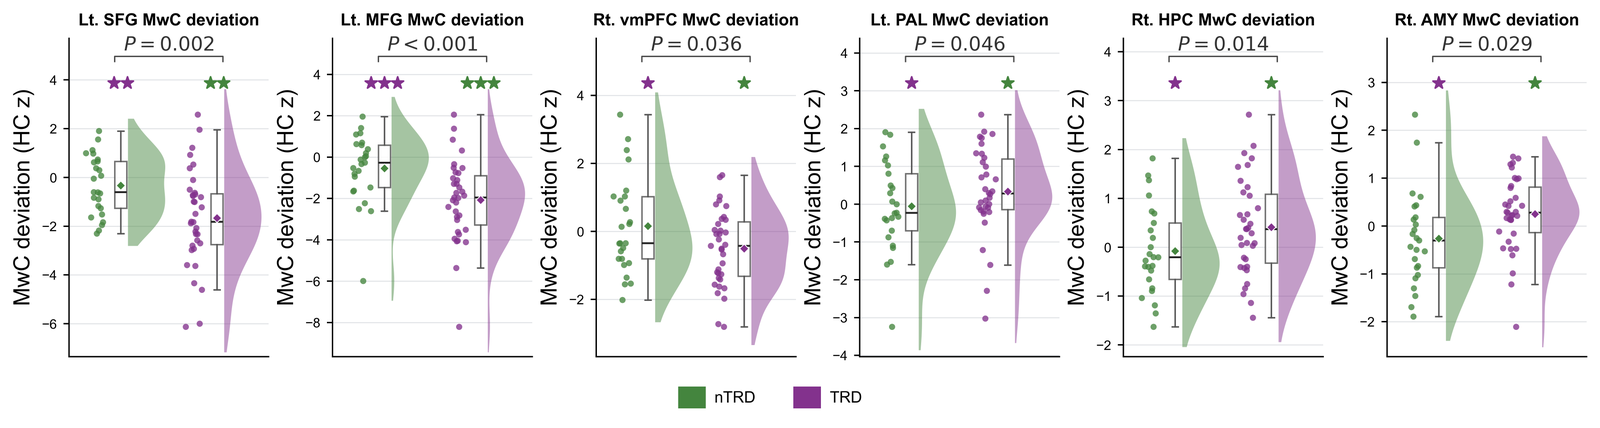

In [5]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'MwC values and adjusted group statistics', 'path': 'outputs/mwc/ntrd_vs_trd_selected_unilateral_mwc_deviation_age_sex.csv'}]
_inline_figure_paths = ['outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
